In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
df = pd.read_csv('house_price_dataset_with_floors.csv')
df.head()

,Area,Bedrooms,Bathrooms,Parking,City,Price,Floors
0,702,2,2,1,Mumbai,10820000,2
1,2833,5,4,0,Mumbai,41940000,2
2,1495,3,2,1,Mumbai,22880000,3
3,2318,4,4,0,Chennai,16600000,2
4,2331,4,4,1,Bangalore,22660000,1


In [34]:
df.isnull().sum()


Area         0
Bedrooms     0
Bathrooms    0
Parking      0
City         0
Price        0
Floors       0
dtype: int64

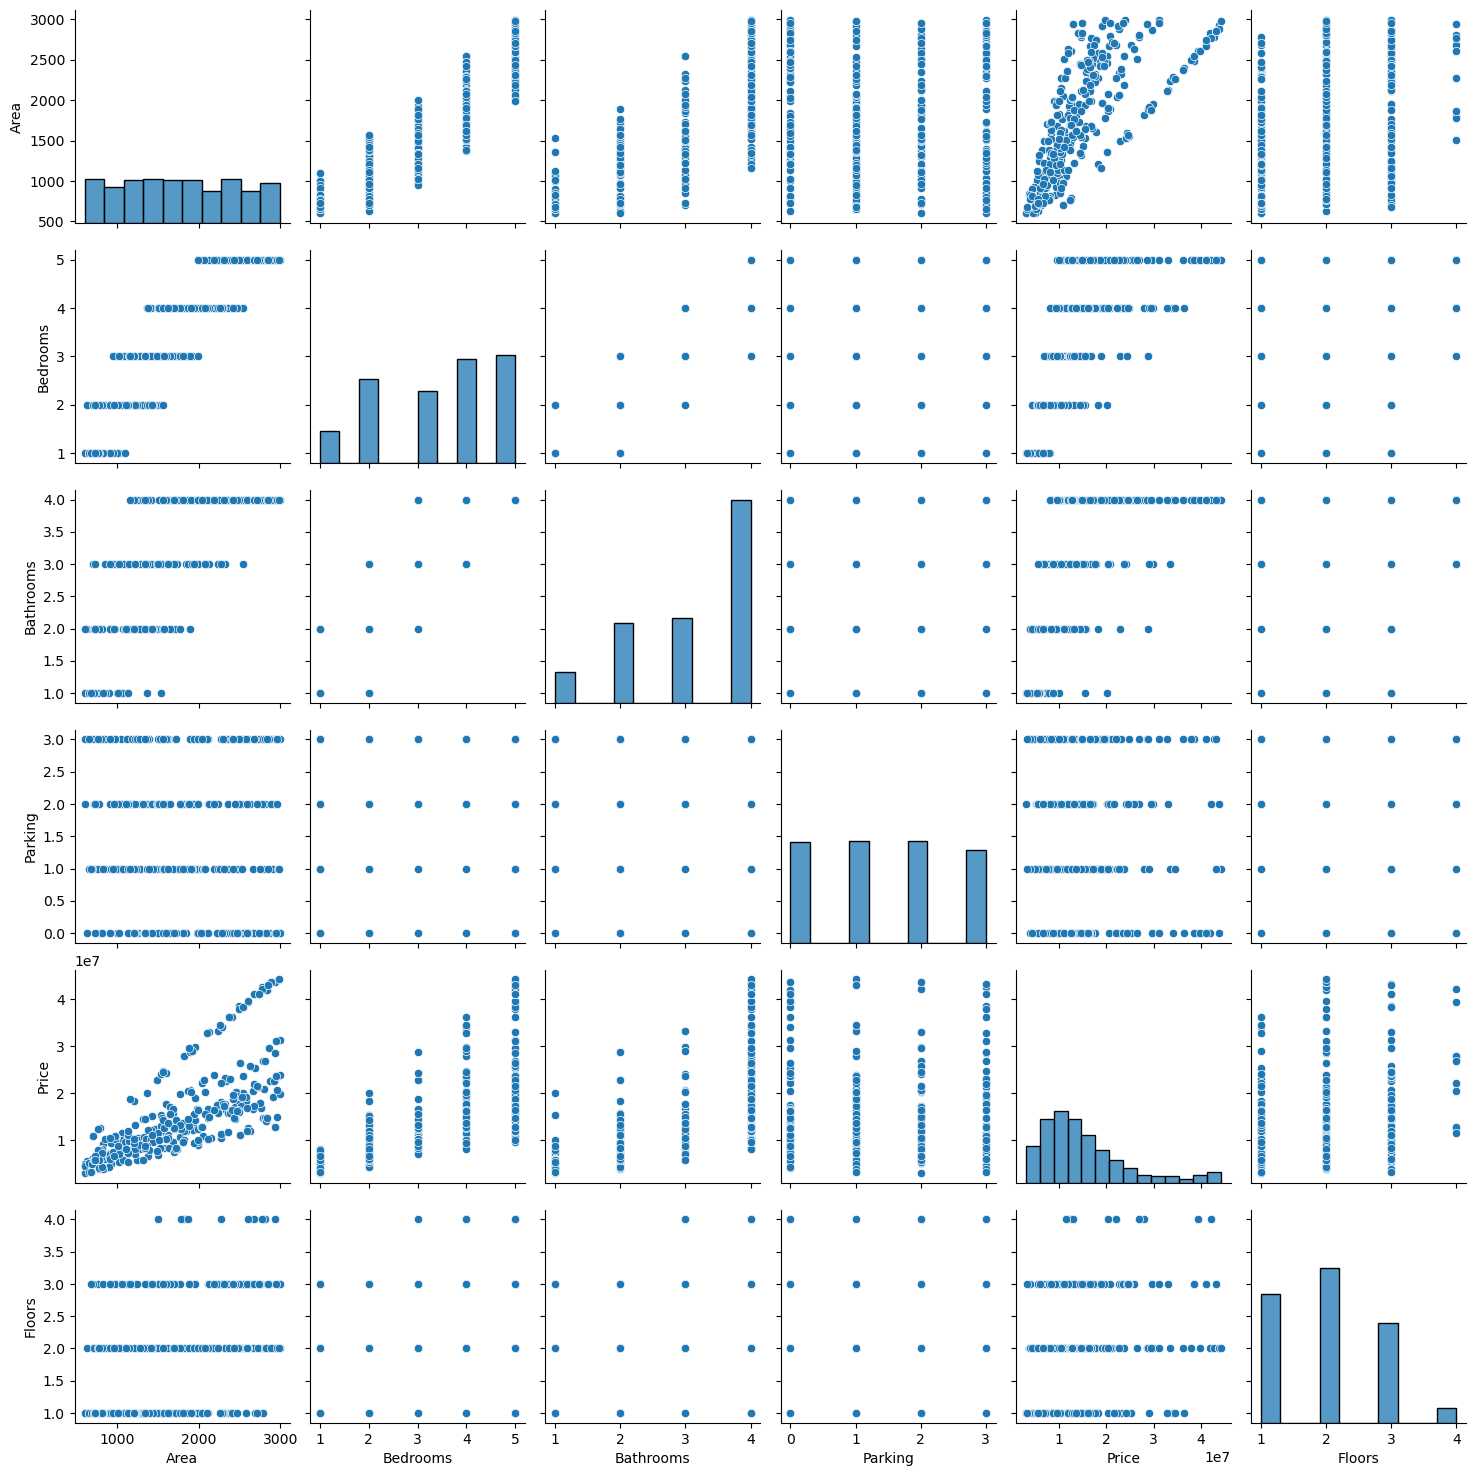

In [35]:

sns.pairplot(df)

In [54]:
X = df[["Area","Bedrooms","Bathrooms","Parking","City","Floors"]]
y = df["Price"]

In [55]:
X


,Area,Bedrooms,Bathrooms,Parking,City,Floors
0,702,2,2,1,Mumbai,2
1,2833,5,4,0,Mumbai,2
2,1495,3,2,1,Mumbai,3
3,2318,4,4,0,Chennai,2
4,2331,4,4,1,Bangalore,1
...,...,...,...,...,...,...
295,2427,4,4,3,Pune,3
296,1155,3,4,1,Mumbai,3
297,959,2,2,2,Kolkata,2
298,2852,5,4,1,Mumbai,3


In [56]:
y

0      10820000
1      41940000
2      22880000
3      16600000
4      22660000
         ...   
295    19550000
296    18810000
297     6540000
298    43070000
299    20310000
Name: Price, Length: 300, dtype: int64

In [57]:
df['City'].unique()

array(['Mumbai', 'Chennai', 'Bangalore', 'Jaipur', 'Lucknow', 'Hyderabad',
       'Pune', 'Delhi', 'Noida', 'Kolkata'], dtype=object)

In [59]:
from sklearn.preprocessing import OneHotEncoder
encoded = OneHotEncoder(sparse_output=False,handle_unknown="ignore")
city_encoded = encoded.fit_transform(df[['City']])
print(city_encoded.shape)
print(encoded.get_feature_names_out(['City']))

(300, 10)
['City_Bangalore' 'City_Chennai' 'City_Delhi' 'City_Hyderabad'
 'City_Jaipur' 'City_Kolkata' 'City_Lucknow' 'City_Mumbai' 'City_Noida'
 'City_Pune']


In [60]:
city_encoded_df = pd.DataFrame(
    city_encoded,
    columns=encoded.get_feature_names_out(["City"])
)

print(city_encoded_df.head())

   City_Bangalore  City_Chennai  City_Delhi  City_Hyderabad  City_Jaipur  \
0             0.0           0.0         0.0             0.0          0.0   
1             0.0           0.0         0.0             0.0          0.0   
2             0.0           0.0         0.0             0.0          0.0   
3             0.0           1.0         0.0             0.0          0.0   
4             1.0           0.0         0.0             0.0          0.0   

   City_Kolkata  City_Lucknow  City_Mumbai  City_Noida  City_Pune  
0           0.0           0.0          1.0         0.0        0.0  
1           0.0           0.0          1.0         0.0        0.0  
2           0.0           0.0          1.0         0.0        0.0  
3           0.0           0.0          0.0         0.0        0.0  
4           0.0           0.0          0.0         0.0        0.0  


In [61]:
X_num = X[['Area','Bedrooms','Bathrooms','Parking','Floors']]
X_final = pd.concat([X_num.reset_index(drop=True),city_encoded_df.reset_index(drop=True)],axis=1)

In [62]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X_final,y,test_size=0.30,random_state=42)



In [63]:
from sklearn.linear_model import LinearRegression
regression = LinearRegression(n_jobs=-1)

In [64]:
regression.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,-1
,positive,False


In [65]:
y_pred = regression.predict(X_test)

In [69]:
area = 14000
bedrooms = 4
bathrooms = 3
parking = 2
city = "BLB"
floors = 2
new_city = encoded.transform([[city]])
new_city_df = pd.DataFrame(new_city,columns=encoded.get_feature_names_out(['City']))
new_house = pd.DataFrame({
    'Area' : [area],
    'Bedrooms' : [bedrooms],
    'Bathrooms' : [bathrooms],
    'Parking' : [parking],
    'Floors' : [floors]
})

c:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but OneHotEncoder was fitted with feature names
  warnings.warn(


In [70]:
new_dataset = pd.concat([new_house,new_city_df],axis=1)
print(regression.coef_)
print(X_final.columns)

[ 8.76965452e+03 -3.28706699e+05 -1.02610205e+05  1.25812211e+05
  3.30661552e+04  2.41610103e+06 -1.62485857e+06  4.00712568e+06
 -1.02568261e+06 -5.58657326e+06 -3.42147493e+06 -6.02624189e+06
  1.43208341e+07 -2.74636065e+06 -3.12868953e+05]
Index(['Area', 'Bedrooms', 'Bathrooms', 'Parking', 'Floors', 'City_Bangalore',
       'City_Chennai', 'City_Delhi', 'City_Hyderabad', 'City_Jaipur',
       'City_Kolkata', 'City_Lucknow', 'City_Mumbai', 'City_Noida',
       'City_Pune'],
      dtype='object')


In [71]:
pred_price = regression.predict(new_dataset)
print("Price: ")
print(pred_price[0])

Price: 
121955676.92556825


In [72]:
import joblib
joblib.dump(regression,"house_model.pkl")

['house_model.pkl']